<a href="https://colab.research.google.com/github/eaedk/Machine-Learning-Tutorials-Updated/blob/main/01_tabular/02_classification_app_telco_churn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📡 Application · Tabular classification: Who is about to leave? (Telecom churn)

In telecom, a customer who leaves (*churns*) is expensive: winning a new one costs **5 to 7 times** more than keeping
an existing one. Operators across Africa (Orange, MTN, Airtel, Expresso, Safaricom…) run churn models every month to
decide who should receive a retention offer. Zindi even hosted the
[Expresso Churn Prediction Challenge](https://zindi.africa/competitions/expresso-churn-prediction) with data from a
Senegalese operator.

Here we use the public **IBM Telco Customer Churn** dataset (7 043 customers, also famous on Kaggle): contract,
services, charges… and whether the customer left last month.

**Metric:** ROC AUC, as in most churn competitions. It measures how well the model **ranks** customers from "will
stay" to "will leave", which is exactly what a marketing team needs to target the riskiest ones.

**What's new compared to the Titanic quest**
- 🧹 real-world dirty data (text numbers, quotes, blanks)
- 🌳 gradient boosting libraries: **LightGBM, XGBoost, CatBoost**, the kings of tabular competitions
- 🎛️ hyperparameter search with **Optuna**
- 💰 from probabilities to **business decisions** (threshold, profit curve)
- 🔍 explaining predictions with **SHAP**
- 🤝 a final **blend** and an exported pipeline

In [1]:
# ⚙️ Setup: run me first! Finds the course toolkit `mlquest` (Windows, macOS, Linux and Colab).
import os, sys, subprocess, pathlib
if "google.colab" in sys.modules:  # on Colab: grab the repo (once) and the few missing packages
    if not pathlib.Path("/content/Machine-Learning-Tutorials-Updated").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/eaedk/Machine-Learning-Tutorials-Updated", "/content/Machine-Learning-Tutorials-Updated"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "catboost", "optuna", "shap"], check=True)
    os.chdir("/content/Machine-Learning-Tutorials-Updated")
ROOT = pathlib.Path.cwd()
while not (ROOT / "mlquest").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from mlquest import *  # paths, seed_everything, get_device, quest/checkpoint, Leaderboard...
set_style()
SEED = seed_everything(42)

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
quest("Who is about to leave?", chapter="Track 1 · Tabular · Classification (application)", xp=300)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🗺️  QUEST · Who is about to leave?
   Track 1 · Tabular · Classification (application)
   Reward: up to 300 XP
   You are: 🥚 Curious Rookie   ░░░░░░░░░░░░░░░░░░░░░░░░ 0/100 XP
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


## 1. Load and clean 🧹

Real data is never clean. Let's look at what OpenML gives us.

In [3]:
raw = openml(42178)
print(raw.shape)
raw.head(3).T

(7043, 20)


,0,1,2
gender,Female,Male,Male
SeniorCitizen,0,0,0
Partner,Yes,No,No
Dependents,No,No,No
tenure,1,34,2
PhoneService,No,Yes,Yes
MultipleLines,'No phone service',No,No
InternetService,DSL,DSL,DSL
OnlineSecurity,No,Yes,Yes
OnlineBackup,Yes,No,Yes


Three problems jump out:
1. Some category values carry quotes: `'No phone service'`, `'One year'`.
2. `TotalCharges` is a **text** column (it should be a number).
3. `Churn` is `"Yes"`/`"No"`, models want `1`/`0`.

In [4]:
df = raw.copy()
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].str.strip("'")

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")   # blanks become NaN
print("TotalCharges missing:", df["TotalCharges"].isna().sum())
print(df.loc[df["TotalCharges"].isna(), ["tenure", "MonthlyCharges", "TotalCharges"]].head())

TotalCharges missing: 11
      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN


The 11 missing `TotalCharges` all have `tenure == 0`: brand-new customers who have not paid yet. The missing value
is **explainable**: the right fill is `0`, not the median. *Always ask why a value is missing.*

In [5]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df["Churn"] = (df["Churn"] == "Yes").astype(int)
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
print(f"Churn rate: {df['Churn'].mean():.1%}")

Churn rate: 26.5%


**Train / test split.** We keep 20% of customers aside as our private test set (stratified to keep the same churn
rate). All decisions will be made with cross-validation on the 80%.

In [6]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(df, test_size=0.2, stratify=df["Churn"], random_state=SEED)
y, y_test = train.pop("Churn"), test.pop("Churn")
print(train.shape, test.shape)

(5634, 19) (1409, 19)


## 2. EDA: what makes customers leave? 🔍

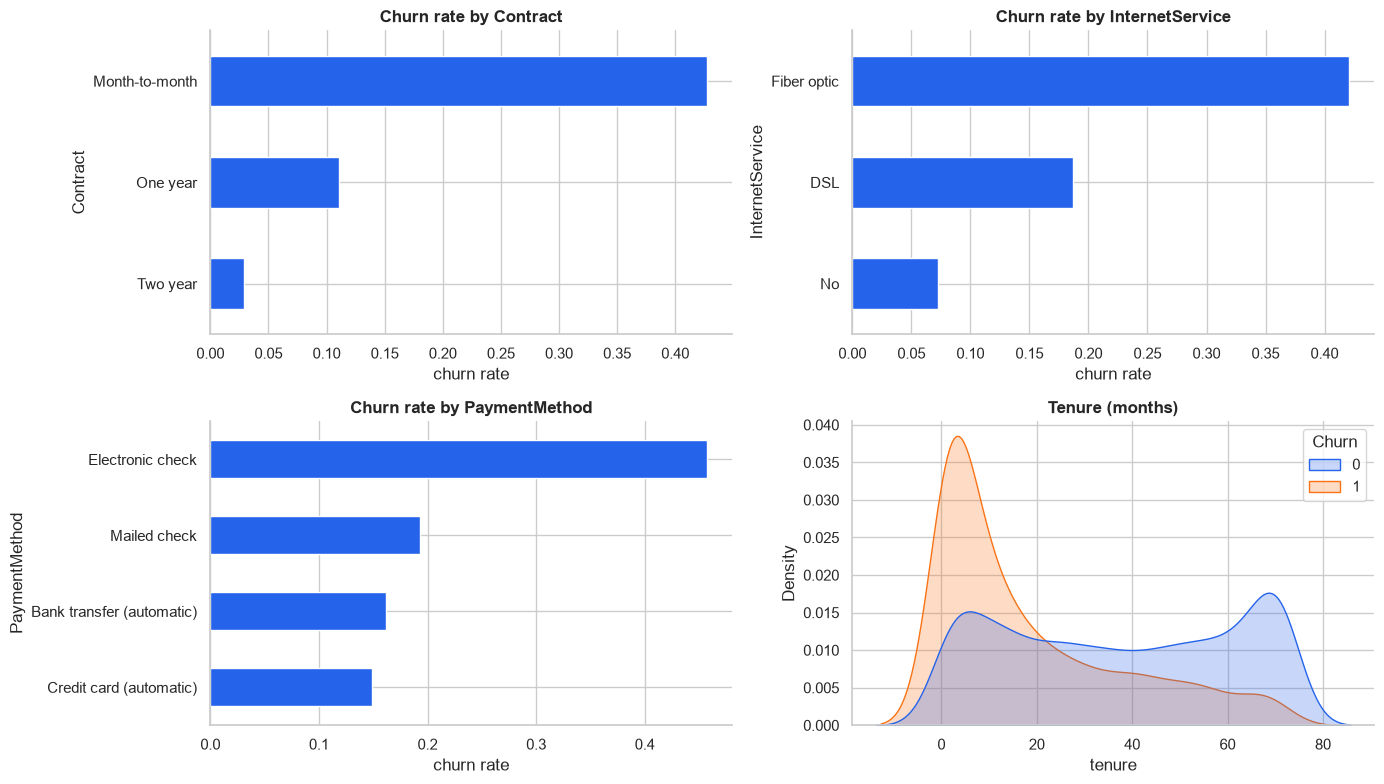

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
tmp = train.assign(Churn=y)
for ax, col in zip(axes.ravel()[:3], ["Contract", "InternetService", "PaymentMethod"]):
    (tmp.groupby(col)["Churn"].mean().sort_values().plot.barh(ax=ax, color="#2563eb"))
    ax.set(title=f"Churn rate by {col}", xlabel="churn rate")
sns.kdeplot(data=tmp, x="tenure", hue="Churn", common_norm=False, fill=True, ax=axes[1, 1]).set(title="Tenure (months)")
plt.tight_layout(); plt.show()

**Conclusions**
- 📄 **Month-to-month** contracts churn ~10× more than two-year contracts: commitment is the strongest signal.
- 🌐 **Fiber optic** users churn more (price? service quality?).
- 💳 **Electronic check** payers churn much more than automatic payments.
- ⏳ Churn happens **early**: most leavers have a short tenure. The first months are critical.

These are already actionable insights for a marketing team, before any model.

## 3. Features 🛠️

A few business-inspired features:
- `n_services`: how many optional services the customer subscribes to (more services → more "locked in"?)
- `avg_monthly_spend` = TotalCharges / tenure: compared with `MonthlyCharges`, it reveals recent price changes.
- `is_new`: tenure ≤ 6 months.

In [8]:
SERVICES = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
            "TechSupport", "StreamingTV", "StreamingMovies"]

def make_features(data: pd.DataFrame) -> pd.DataFrame:
    data = data.copy()
    data["n_services"] = (data[SERVICES] == "Yes").sum(axis=1)
    data["avg_monthly_spend"] = data["TotalCharges"] / data["tenure"].clip(lower=1)
    data["price_change"] = data["MonthlyCharges"] - data["avg_monthly_spend"]
    data["is_new"] = (data["tenure"] <= 6).astype(int)
    return data

X, X_test = make_features(train), make_features(test)
cat_cols = X.select_dtypes(include=["object", "string"]).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
print(f"{len(num_cols)} numeric: {num_cols}\n{len(cat_cols)} categorical")

7 numeric: ['tenure', 'MonthlyCharges', 'TotalCharges', 'n_services', 'avg_monthly_spend', 'price_change', 'is_new']
16 categorical


## 4. Baselines and the gradient boosting trio 🌳

**Gradient boosting** builds hundreds of small decision trees, each one correcting the errors of the previous ones.
Since ~2015 it wins most tabular competitions. Three popular implementations:

| Library | Origin | Strength |
|---|---|---|
| **XGBoost** (2014) | Tianqi Chen, U. Washington | the one that started the Kaggle domination |
| **LightGBM** (2016) | Microsoft | very fast, histogram-based, great default |
| **CatBoost** (2017) | Yandex | handles categorical features natively, robust defaults |

For linear models and XGBoost/LightGBM we one-hot encode categories; CatBoost receives the raw text columns.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

from sklearn.metrics import roc_auc_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
onehot = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

# A model "factory" builds a fresh, untrained model each time it is called.
models = {
    "Dummy": lambda: make_pipeline(onehot, DummyClassifier(strategy="prior")),
    "Logistic Regression": lambda: make_pipeline(onehot, LogisticRegression(max_iter=2000, C=0.5)),
    "LightGBM": lambda: make_pipeline(onehot, LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15,
                                                             subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                                             random_state=SEED, verbose=-1)),
    "XGBoost": lambda: make_pipeline(onehot, XGBClassifier(n_estimators=300, learning_rate=0.03, max_depth=4,
                                                           subsample=0.8, colsample_bytree=0.8, random_state=SEED)),
    "CatBoost": lambda: CatBoostClassifier(iterations=600, learning_rate=0.05, depth=5, cat_features=cat_cols,
                                           random_seed=SEED, verbose=0, allow_writing_files=False),
}


def run_cv(make_model):
    """The competitor's hand-written CV loop: returns out-of-fold probabilities and the AUC of each fold."""
    oof_pred, scores = np.zeros(len(X)), []
    for train_idx, valid_idx in cv.split(X, y):
        model = make_model().fit(X.iloc[train_idx], y.iloc[train_idx])
        oof_pred[valid_idx] = model.predict_proba(X.iloc[valid_idx])[:, 1]
        scores.append(roc_auc_score(y.iloc[valid_idx], oof_pred[valid_idx]))
    return oof_pred, np.array(scores)


lb = Leaderboard("telco_churn", metric="AUC")
oof = {}   # out-of-fold probabilities: each row predicted by a model that never saw it
for name, make_model in models.items():
    oof[name], fold_scores = run_cv(make_model)
    lb.add(name, fold_scores.mean(), std=round(fold_scores.std(), 4))
lb.show()

📋 Dummy: AUC = 0.50000


📋 Logistic Regression: AUC = 0.84754  👑 new best!


📋 LightGBM: AUC = 0.84480


📋 XGBoost: AUC = 0.84634


📋 CatBoost: AUC = 0.84397


,,model,AUC,std
rank,,,,
1,🥇,Logistic Regression,0.84754,0.0112
2,🥈,XGBoost,0.84634,0.0097
3,🥉,LightGBM,0.84480,0.0100
4,,CatBoost,0.84397,0.0107
5,,Dummy,0.50000,0.0000


😲 **The logistic regression is right there with the boosters!** This dataset is small and its signal is mostly
"additive" (contract + tenure + payment method…). Lesson: *always* keep a linear baseline; fancy is not always better.
Notice also that the differences between the top models are about the size of their `std`: they are practically tied.

We wrote the CV loop by hand instead of calling `cross_val_score`: it is a classic competition pattern. It gives
**out-of-fold (OOF) predictions** (each training row predicted by a model trained on the other folds), which let us
evaluate blends and thresholds without touching the test set. The same loop can also average the 5 fold models'
predictions on the test set.

In [10]:
checkpoint("churn/baselines", xp=60)

✅ Checkpoint · churn/baselines (+60 XP)
   ██████████████░░░░░░░░░░ 60/100 XP


## 5. Hyperparameter search with Optuna 🎛️

Grid search tries every combination: slow. **Optuna** (2019) is smarter: it learns from previous trials which regions
of the search space look promising (*Bayesian optimisation* with the TPE algorithm). We give it 30 trials to tune
LightGBM.

Best params: {'n_estimators': 800, 'learning_rate': 0.007256943828726273, 'num_leaves': 5, 'min_child_samples': 26, 'reg_lambda': 0.14537874428533004, 'colsample_bytree': 0.492915799774656}
📋 LightGBM (Optuna): AUC = 0.85070  👑 new best!


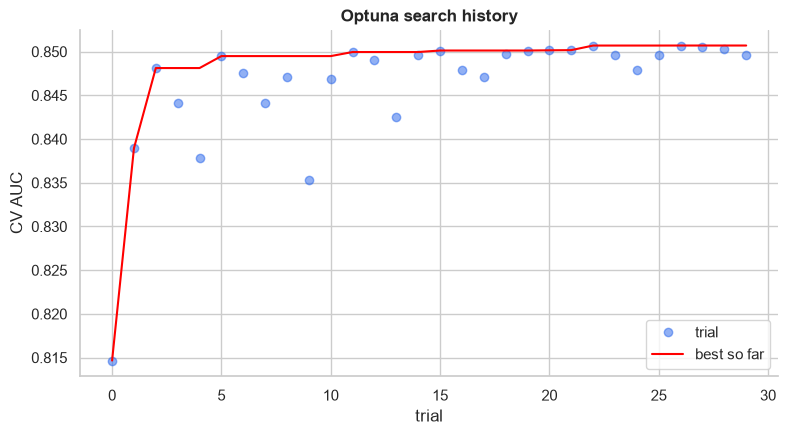

In [11]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = dict(
        n_estimators=trial.suggest_int("n_estimators", 100, 800, step=50),
        learning_rate=trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
        num_leaves=trial.suggest_int("num_leaves", 4, 48),
        min_child_samples=trial.suggest_int("min_child_samples", 10, 120),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        subsample=0.8, subsample_freq=1, random_state=SEED, verbose=-1,
    )
    pipe = make_pipeline(onehot, LGBMClassifier(**params))
    return cross_val_score(pipe, X, y, cv=cv, scoring="roc_auc").mean()

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=30, show_progress_bar=False)
print("Best params:", study.best_params)
lb.add("LightGBM (Optuna)", study.best_value)

trials = study.trials_dataframe()
plt.plot(trials["number"], trials["value"], "o", alpha=0.5, label="trial")
plt.plot(trials["number"], trials["value"].cummax(), "r-", label="best so far")
plt.gca().set(xlabel="trial", ylabel="CV AUC", title="Optuna search history"); plt.legend(); plt.show()

In [12]:
models["LightGBM (Optuna)"] = lambda: make_pipeline(onehot, LGBMClassifier(**study.best_params, subsample=0.8,
                                                                            subsample_freq=1, random_state=SEED, verbose=-1))
oof["LightGBM (Optuna)"], _ = run_cv(models["LightGBM (Optuna)"])

## 6. Blend 🤝

Average the OOF probabilities of models from **different families** (linear + boosting).

In [13]:
pd.DataFrame(oof).drop(columns="Dummy").corr().round(3)

,Logistic Regression,LightGBM,XGBoost,CatBoost,LightGBM (Optuna)
Logistic Regression,1.000,0.954,0.962,0.953,0.980
LightGBM,0.954,1.000,0.992,0.981,0.977
XGBoost,0.962,0.992,1.000,0.984,0.985
CatBoost,0.953,0.981,0.984,1.000,0.972
LightGBM (Optuna),0.980,0.977,0.985,0.972,1.000


In [14]:
blend_members = ["Logistic Regression", "LightGBM (Optuna)", "CatBoost"]
oof_blend = np.mean([oof[m] for m in blend_members], axis=0)
blend_cv = roc_auc_score(y, oof_blend)
lb.add("Blend (LogReg + LGBM + CatBoost)", blend_cv)
lb.show()

📋 Blend (LogReg + LGBM + CatBoost): AUC = 0.84962


,,model,AUC,std
rank,,,,
1,🥇,LightGBM (Optuna),0.85070,NaN
2,🥈,Blend (LogReg + LGBM + CatBoost),0.84962,NaN
3,🥉,Logistic Regression,0.84754,0.0112
4,,XGBoost,0.84634,0.0097
5,,LightGBM,0.84480,0.0100
6,,CatBoost,0.84397,0.0107
7,,Dummy,0.50000,0.0000


Look at the correlation matrix: the models agree at 95-99%. When members are that similar, a blend can't do much
better than the best of them, and in CV it lands right next to the tuned LightGBM. Blends shine when members are
**diverse** (different features, different algorithms, a neural network…). We still keep the blend for the final
submission: averaging is a cheap insurance against one model being unlucky on new data.

In [15]:
checkpoint("churn/blend", xp=60)

✅ Checkpoint · churn/blend (+60 XP)
🎉 LEVEL UP! You are now 🐣 Data Explorer
   ██░░░░░░░░░░░░░░░░░░░░░░ 120/300 XP


## 7. From probabilities to decisions 💰

A churn score is useless until someone acts on it. Suppose:
- a retention offer (discount, bonus data) costs **10 €** per targeted customer,
- it convinces **30%** of real churners to stay,
- a retained customer is worth **200 €** (future margin).

Who should we target? Everyone above a probability **threshold**. Let's compute the profit for every threshold on the
OOF predictions.

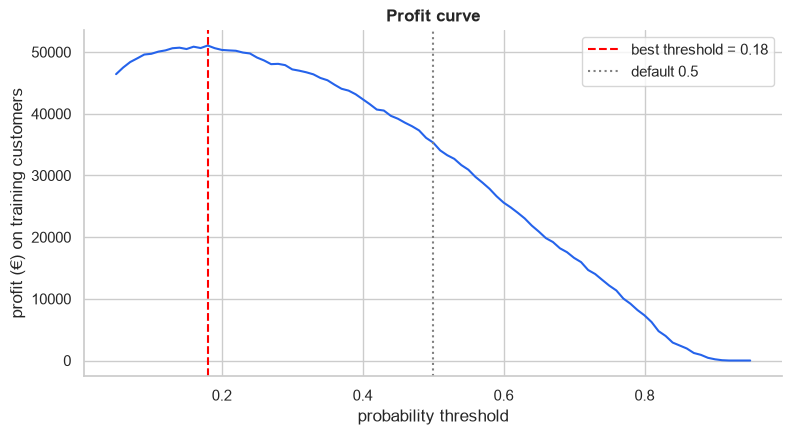

Best threshold 0.18: profit 51,060 € vs 35,330 € at 0.5


In [16]:
OFFER_COST, SUCCESS_RATE, CUSTOMER_VALUE = 10, 0.30, 200
thresholds = np.linspace(0.05, 0.95, 91)
profits = []
for t in thresholds:
    targeted = oof_blend >= t
    saved = (targeted & (y.to_numpy() == 1)).sum() * SUCCESS_RATE
    profits.append(saved * CUSTOMER_VALUE - targeted.sum() * OFFER_COST)
best_t = thresholds[int(np.argmax(profits))]

plt.plot(thresholds, profits)
plt.axvline(best_t, color="red", ls="--", label=f"best threshold = {best_t:.2f}")
plt.axvline(0.5, color="gray", ls=":", label="default 0.5")
plt.gca().set(xlabel="probability threshold", ylabel="profit (€) on training customers", title="Profit curve")
plt.legend(); plt.show()
print(f"Best threshold {best_t:.2f}: profit {max(profits):,.0f} € vs {profits[45]:,.0f} € at 0.5")

The best threshold is far below 0.5: the offer is cheap compared to the value of a customer, so it pays to target
broadly. **The metric of the competition (AUC) is not the metric of the business (profit)**: always ask what the
predictions will be used for.

## 8. Why does the model say that? 🔍 (SHAP)

**SHAP** values (Lundberg & Lee, 2017, based on game theory's Shapley values from 1953) split each prediction into the
contribution of each feature. Red = high feature value, blue = low; right = pushes towards churn.

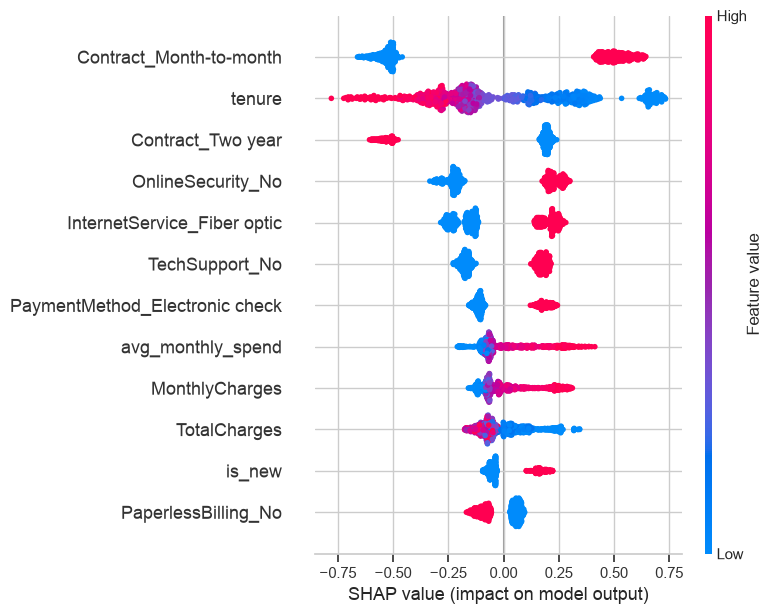

In [17]:
import shap

best_lgbm = models["LightGBM (Optuna)"]().fit(X, y)
Xt = best_lgbm[0].transform(X)
feature_names = best_lgbm[0].get_feature_names_out()
explainer = shap.TreeExplainer(best_lgbm[-1])
sample = Xt[:1000].toarray() if hasattr(Xt, "toarray") else Xt[:1000]
shap_values = explainer.shap_values(sample)
shap.summary_plot(shap_values, sample, feature_names=[f.split("__")[1] for f in feature_names], max_display=12, show=False)
plt.tight_layout(); plt.show()

The model confirms the EDA: short tenure, month-to-month contracts, fiber optic and electronic check push towards
churn; long tenure and two-year contracts protect. A model you can explain is a model a business will trust.

## 9. Final evaluation and export 📤

Refit the three blend members on all training data, predict the hidden test set, and save everything.

In [18]:
import joblib

final = {name: models[name]() for name in blend_members}
test_probas = {name: m.fit(X, y).predict_proba(X_test)[:, 1] for name, m in final.items()}
test_blend = np.mean(list(test_probas.values()), axis=0)

for name, p in test_probas.items():
    print(f"{name:<22} test AUC = {roc_auc_score(y_test, p):.4f}")
print(f"{'Blend':<22} test AUC = {roc_auc_score(y_test, test_blend):.4f}   (CV said {blend_cv:.4f})")

submission = pd.DataFrame({"customer_id": test.index, "churn_probability": test_blend.round(5)})
make_submission(submission, "telco_churn_submission.csv")
joblib.dump({"models": final, "features": make_features, "threshold": best_t}, RUNS_DIR / "telco_churn_blend.joblib")
print("💾 Saved runs/telco_churn_blend.joblib: load it in a Streamlit/Gradio app to score new customers.")

Logistic Regression    test AUC = 0.8459
LightGBM (Optuna)      test AUC = 0.8473
CatBoost               test AUC = 0.8417
Blend                  test AUC = 0.8479   (CV said 0.8496)
📤 Submission saved: submissions/telco_churn_submission.csv  (1409 rows, columns=['customer_id', 'churn_probability'])
💾 Saved runs/telco_churn_blend.joblib: load it in a Streamlit/Gradio app to score new customers.


## 🏁 Mission accomplished

You cleaned real data, compared five model families, tuned with Optuna, blended, turned probabilities into a
business decision, explained the model and exported it.

### 🚀 Your turn
1. **Feature hunt:** add `MonthlyCharges / n_services` or interactions like `Contract × InternetService`. Does the CV move
   more than its `std`?
2. **Imbalance:** try `class_weight="balanced"` (LogReg/LightGBM) or `auto_class_weights="Balanced"` (CatBoost). What
   happens to AUC? To the profit curve?
3. **Business what-if:** set the offer cost to 50 € and the success rate to 10%. Where does the best threshold go?
4. **Go compete:** apply the same recipe to Zindi's
   [Expresso Churn Prediction](https://zindi.africa/competitions/expresso-churn-prediction) challenge.

In [19]:
checkpoint("churn/complete", xp=180)
badge("Churn Buster", "📡")
progress()

✅ Checkpoint · churn/complete (+180 XP)
🎉 LEVEL UP! You are now 🧭 Feature Pathfinder
   ░░░░░░░░░░░░░░░░░░░░░░░░ 300/600 XP
╔═════════════════════════════════╗
║ 📡  BADGE UNLOCKED: Churn Buster ║
╚═════════════════════════════════╝
🧭 Feature Pathfinder
░░░░░░░░░░░░░░░░░░░░░░░░ 300/600 XP
Checkpoints unlocked: 3
Badges: 📡 Churn Buster
